# Análise Exploratória sobre dados de exoplanetas catalogados pelo NASA

Este conjunto de dados abrange, sem duplicatas ou registros corrompidos, os 6445 exoplanetas (planeta que orbita uma estrela que não é o nosso Sol) confirmados catalogados pelo NASA Exoplanet Archive (IPAC/Caltech) até outubro de 2026, contemplando dinâmicas orbitais, propriedades planetárias globais, parâmetros das estrelas hospedeiras e métricas multidimensionais de habitabilidade.

## Análise exploratória de dados


A análise exploratória de dados (AED) visa descobrir aspectos de maior interesse através da exploração dos dados, com estes sendo representados de modo a destacar padrões que podem ou não se confirmar inferencialmente.


In [134]:
import pandas as pd
df = pd.read_csv('exoplanetas_colunas_selecionadas.csv')

## Detalhando as variáveis do conjunto de dados dos exoplanetas:

- **nome_planeta:**

  Nome oficial (IAU) do exoplaneta ou designação atribuída por ocasião de sua descoberta. São exemplos "CD-35 2722 B b" e "DMPP-2 c".
- **nome_estrela_primaria:**
  
  Nome da estrela principal em torno da qual o planeta orbita. São exemplos "CD-35 2722 B" e "DMPP-2".
- **metodo_descoberta:**

  Método principal de detecção observacional, podendo ser: "Trânsito", baseado em diminuições na luz das estrelas causadas por planetas em órbita; "Microlente Gravitacional", em que as massas de exoplanetas e suas estrelas distorcem o tecido do espaço-tempo, fazendo com que a luz de estrelas de fundo siga a curvatura, permitindo a detecção de novos sistemas; "Velocidade Radial", que detecta exoplanetas medindo as pequenas alterações na luz de uma estrela (por efeito Doppler) causadas pela oscilação gravitacional que o planeta exerce sobre ela; ou "Outros".

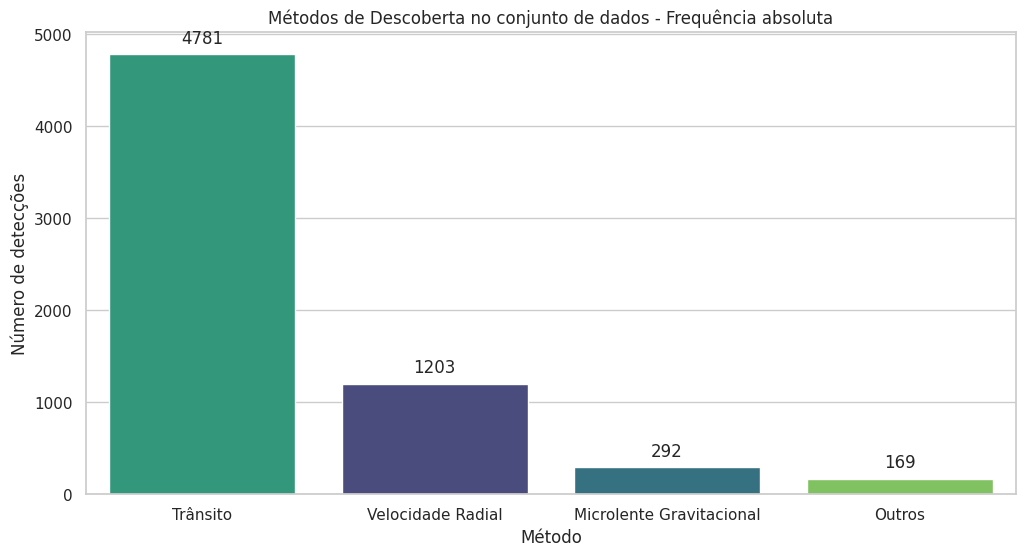

In [135]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

ay = sns.countplot(
    data=df,
    x='metodo_descoberta',
    order=df['metodo_descoberta'].value_counts().index,
    palette='viridis',
    hue='metodo_descoberta',
    legend=False,
)
for container in ay.containers:
    ay.bar_label(container, padding=5)

plt.title('Métodos de Descoberta no conjunto de dados - Frequência absoluta')
plt.ylabel('Número de detecções')
plt.xlabel('Método')

plt.show()

- **ano_descoberta:**
  
  Ano em que a descoberta do planeta foi oficialmente anunciada e confirmada (1992 a 2026).

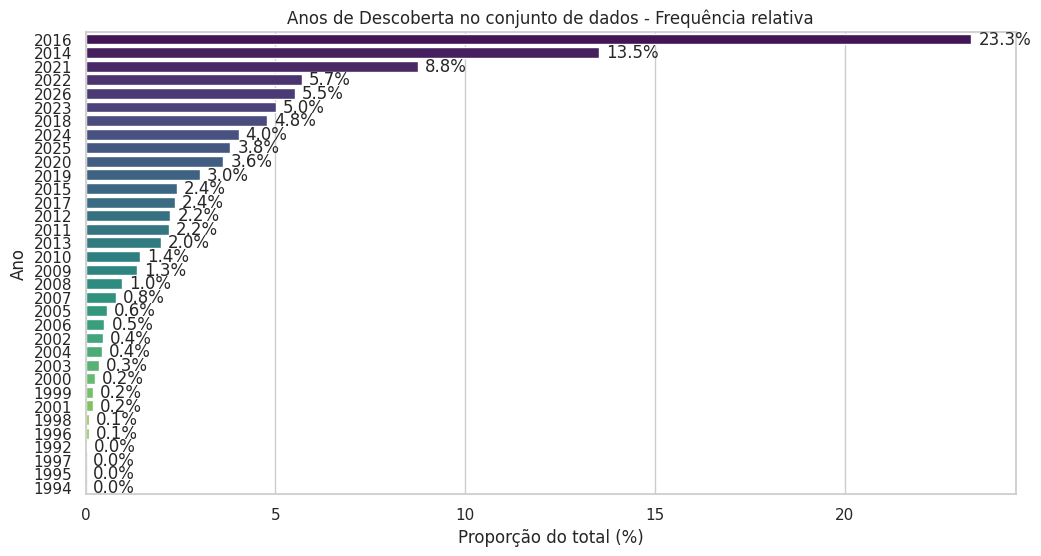

In [136]:
freq_relativa = df['ano_descoberta'].value_counts(normalize=True) * 100
df_perc = freq_relativa.reset_index()
df_perc.columns = ['ano_descoberta', 'porcentagem']
df_perc['ano_descoberta'] = df_perc['ano_descoberta'].astype(str)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df_perc,
    x='porcentagem',
    y='ano_descoberta',
    order=df_perc['ano_descoberta'],
    palette='viridis',
    hue='ano_descoberta',
    legend=False,
    orient='h'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=5)

plt.title('Anos de Descoberta no conjunto de dados - Frequência relativa')
plt.xlabel('Proporção do total (%)')
plt.ylabel('Ano')

plt.show()

- **observatorio_descoberta:**

  Missão espacial ou observatório astronômico em solo ao qual se atribui a detecção inicial, por exemplo, "Satélite de Pesquisa de Exoplanetas em Trânsito (TESS)".

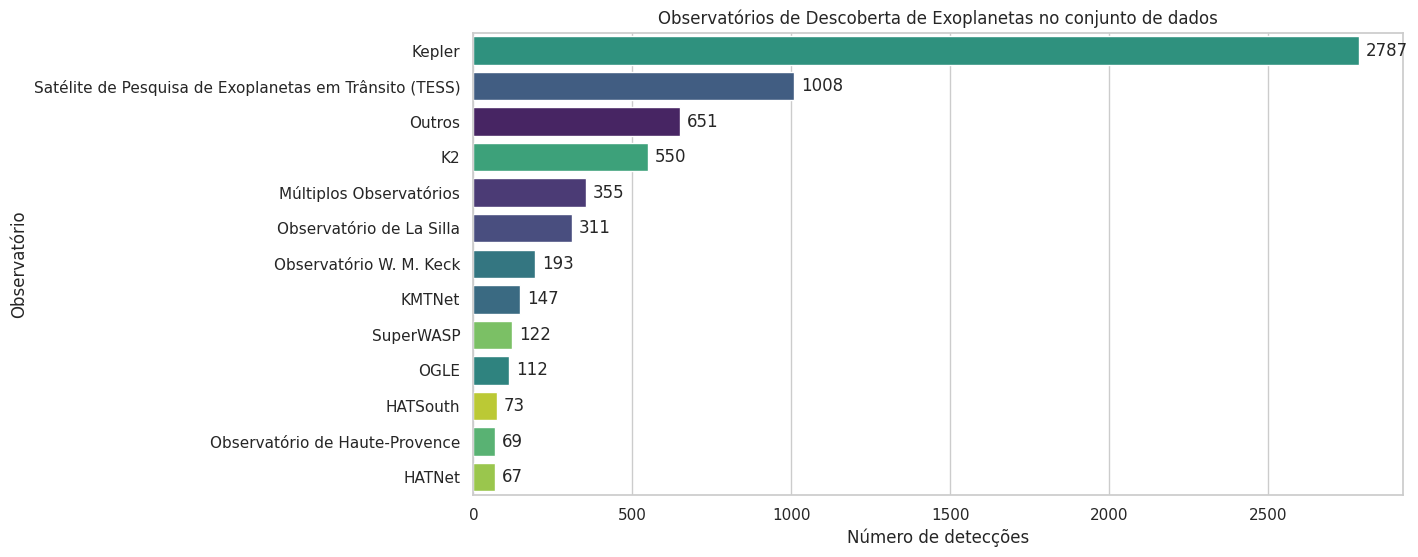

In [137]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    y='observatorio_descoberta',
    order=df['observatorio_descoberta'].value_counts().index,
    palette='viridis',
    hue='observatorio_descoberta',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=5)

plt.title('Observatórios de Descoberta de Exoplanetas no conjunto de dados')
plt.xlabel('Número de detecções')
plt.ylabel('Observatório')

plt.show()

- **periodo_orbital:**

  Período orbital em que o planeta completa uma volta ao redor de sua estrela, expresso em dias terrestres.
- **raio_planetario:**

  Raio do planeta medido em unidades de raios terrestres (o raio da Terra mede cerca de 6371 quilômetros).
- **massa_planetaria:**

  Massa do planeta ou massa mínima, expressa em unidades de massas terrestres (a massa da Terra é por volta de 5,97 sextilhões de toneladas).
- **temp_equilibrio_superf_planetaria:**

  Temperatura de equilíbrio da superfície planetária em Kelvin (K = ºC + 273,15).
- **temp_superf_estelar:**

  Temperatura da superfície (fotosfera) da estrela, em Kelvin.
- **distancia_sistema:**

  Distância do Sistema Solar a esse sistema estelar, medida em parsecs (um parsec equivale a 3,26 anos-luz, 206000 unidades astronômicas, ou então 30,9 trilhões de quilômetros).

- **arquetipo_planetario:**

  Arquétipo (classe) estrutural do planeta, o qual pode ser: "Sub-Netuno/Mini gasoso", com raio_planetario entre 2 e 4 raios terrestres; "Gigante gasoso/Júpiter", de 4 a 15 raios terrestres; "Superterra", de 1,25 a 2 raios terrestres; "Terrestre Rochoso", com menos de 1,25 raio terrestre; "Super-Júpiter Extremo", com mais que 15 raios terrestres.


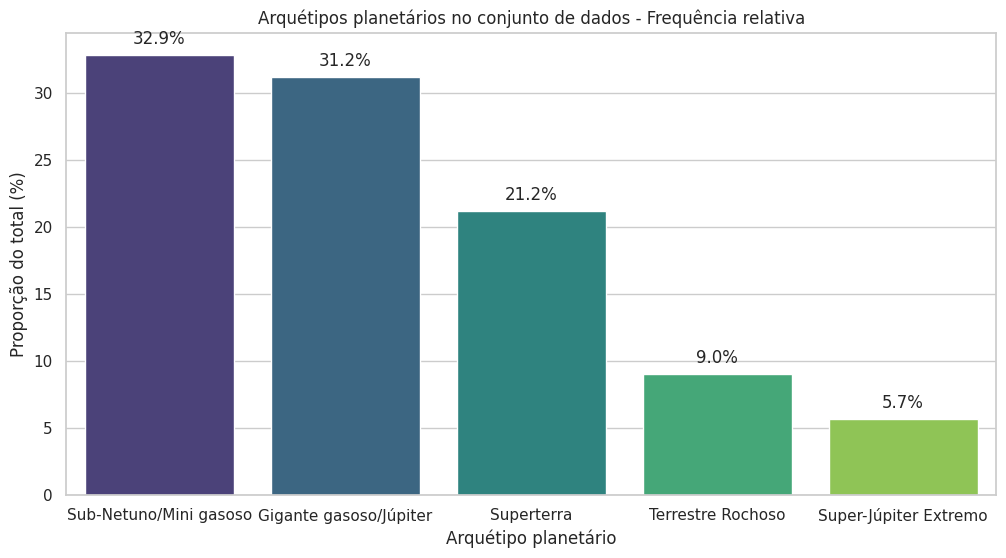

In [138]:
freq_relativa = df['arquetipo_planetario'].value_counts(normalize=True) * 100
df_perc = freq_relativa.reset_index()
df_perc.columns = ['arquetipo_planetario', 'porcentagem']

df_perc['arquetipo_planetario'] = df_perc['arquetipo_planetario'].astype(str)

plt.figure(figsize=(12, 6))

ay = sns.barplot(
    data=df_perc,
    x='arquetipo_planetario',
    y='porcentagem',
    order=df_perc['arquetipo_planetario'],
    palette='viridis',
    hue='arquetipo_planetario',
    legend=False,
)

for container in ay.containers:
    ay.bar_label(container, fmt='%.1f%%', padding=5)

plt.title('Arquétipos planetários no conjunto de dados - Frequência relativa')
plt.ylabel('Proporção do total (%)')
plt.xlabel('Arquétipo planetário')

plt.show()

- **zona_habitabilidade_termica:**

  Regime térmico do planeta, o qual pode ser: "Infernal", com temp_equilibrio_superf_planetaria superior a 500 Kelvin; "Morno/Temperado", entre 320 e 500 K; "Gélido/Criogênico", inferior a 200 K; "Zona Habitável Conservadora", de 200 a 320 K.

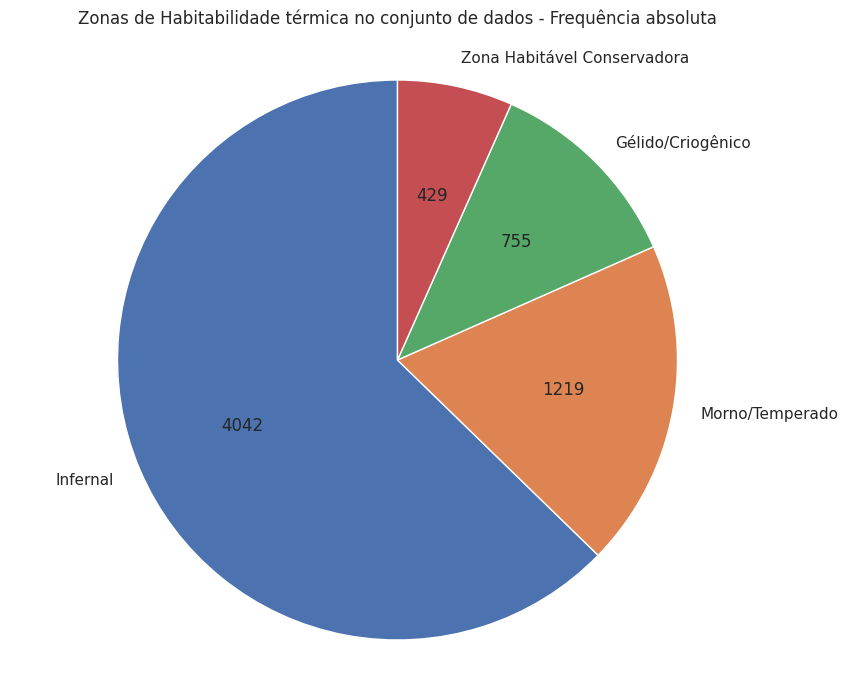

In [139]:
contagem = df['zona_habitabilidade_termica'].value_counts()
total = contagem.sum()

def exibe_valor_absoluto(porcentagem):
    valor_real = int(round(porcentagem * total / 100.0))
    return str(valor_real)

plt.figure(figsize=(10, 8))

plt.pie(
    x=contagem,
    labels=contagem.index,
    autopct=exibe_valor_absoluto,
    startangle=90,
)

plt.title('Zonas de Habitabilidade térmica no conjunto de dados - Frequência absoluta', pad=20)
plt.axis('equal')

plt.show()

- **nivel_arquitetura_orbital:**

  Categoria de dinâmica orbital do planeta, a qual pode ser: "Sistema Interno Compacto", com período orbital de 1 a 10 dias terrestres; "Órbita na Zona Habitável", de 10 a 400 dias; "Sistema Externo Frio", superior a 400 dias; "Período Ultracurto", inferior a 1 dia.

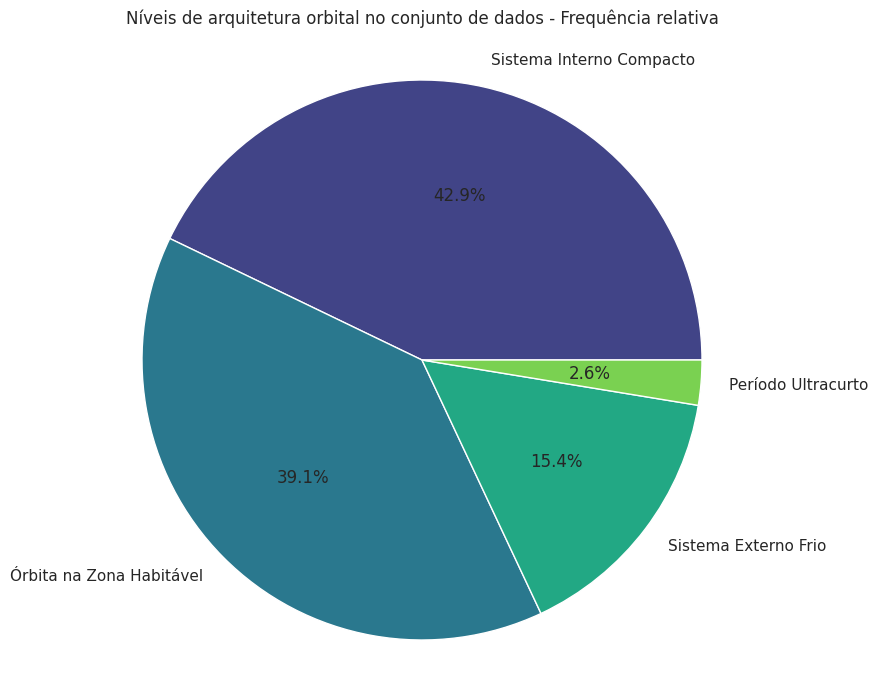

In [140]:
import matplotlib.pyplot as plt
import seaborn as sns

contagem = df['nivel_arquitetura_orbital'].value_counts()

plt.figure(figsize=(10, 8))

plt.pie(
    x=contagem,
    labels=contagem.index,
    autopct='%1.1f%%',
    colors=sns.color_palette('viridis', len(contagem))
)

plt.title('Níveis de arquitetura orbital no conjunto de dados - Frequência relativa', pad=20)
plt.axis('equal')

plt.show()

- **classe_estelar:**

  Categoria espectral da estrela, a qual pode ser: "Análoga ao Sol (Anã Classe G)", com temp_superf_estelar de 5200 a 6000 Kelvin; "Anã Laranja (Classe K)", entre 3700 a 5200 K; "Estrela Massiva Quente (Classes F/A)", superior a 6000 K; "Anã Vermelha (Classe M)", inferior a 3700 K.

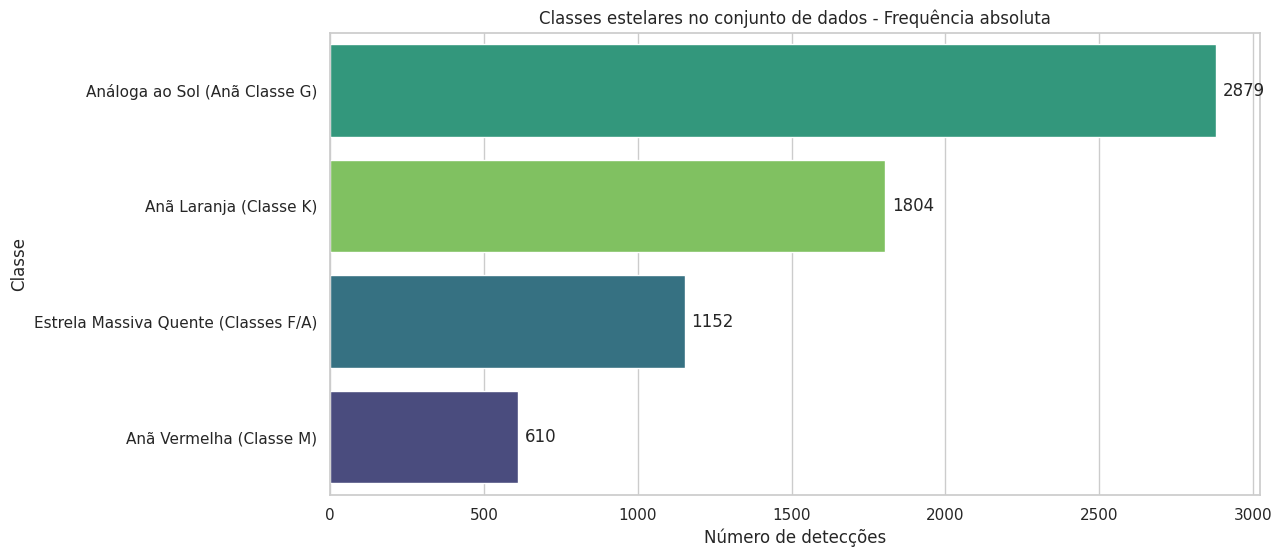

In [141]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    y='classe_estelar',
    order=df['classe_estelar'].value_counts().index,
    palette='viridis',
    hue='classe_estelar',
    legend=False,
)
for container in ax.containers:
    ax.bar_label(container, padding=5)

plt.title('Classes estelares no conjunto de dados - Frequência absoluta')
plt.xlabel('Número de detecções')
plt.ylabel('Classe')

plt.show()

## Gráfico de Mosaico

Visando avaliar a relação entre os dois principais Métodos de Descoberta (Trânsito e Velocidade Radial) e os arquétipos de exoplanetas que eles identificam, fez-se uso da estrutura do mosaico, que permite analisar simultaneamente o volume total de planetas descobertos por cada método, representado pela largura das colunas, e a proporção interna dos tipos planetários encontrados por essas técnicas, representada pela altura dos blocos.


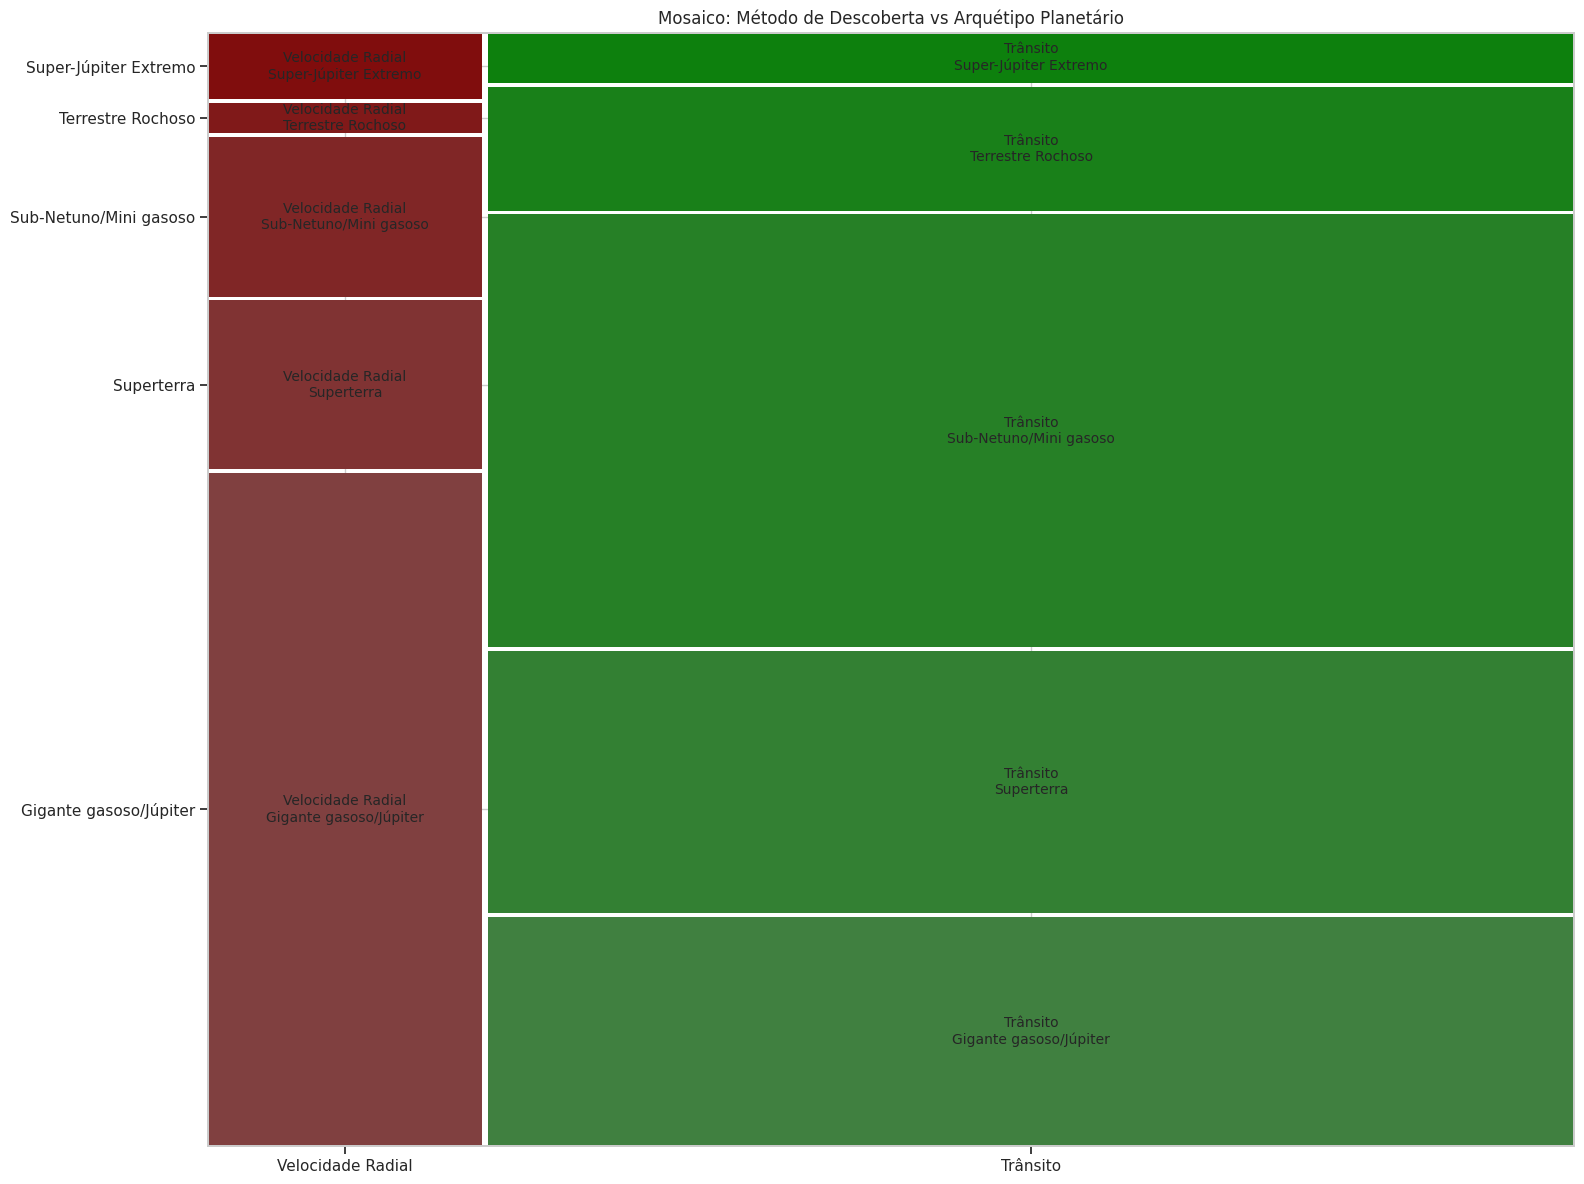

In [142]:
import matplotlib.pyplot as plt
from statsmodels.graphics.mosaicplot import mosaic

metodos_principais = ['Trânsito', 'Velocidade Radial']
df_mosaico = df[df['metodo_descoberta'].isin(metodos_principais)]

fig, ax = plt.subplots(figsize=(16, 12))

mosaic(
    df_mosaico,
    ['metodo_descoberta', 'arquetipo_planetario'],
    ax=ax,
    title='Mosaico: Método de Descoberta vs Arquétipo Planetário'
)


plt.tight_layout()
plt.show()

A largura consideravelmente maior da coluna da direita deixa claro que o método de Trânsito é responsável pela grande maioria das descobertas catalogadas; as detecções feitas por Trânsito concentram-se bastante no arquétipo "Sub-Netuno/Mini gasoso", que ocupa a maior área vertical da coluna. Embora o método de Velocidade Radial apresente um volume de descobertas bem menor (associado a uma coluna mais estreita), sua distribuição interna é altamente enviesada para a detecção de "Gigantes gasosos/Júpiter".

## Zonas de habitabilidade térmica

É possível visualizar a relação entre a classificação zona_habitabilidade_termica de um exoplaneta e seus valores de temp_equilibrio_superf_planetaria e periodo_orbital (pela Terceira Lei de Kepler, o período é proporcional a distância do planeta a sua estrela, o que influencia seu em regime térmico). Naturalmente, quanto maior a temperatura da superfície, mais quente é o regime térmico do planeta, também podendo ser relacionado a isso menores períodos orbitais (maior proximidade a estrela orbitada) dos exoplanetas.

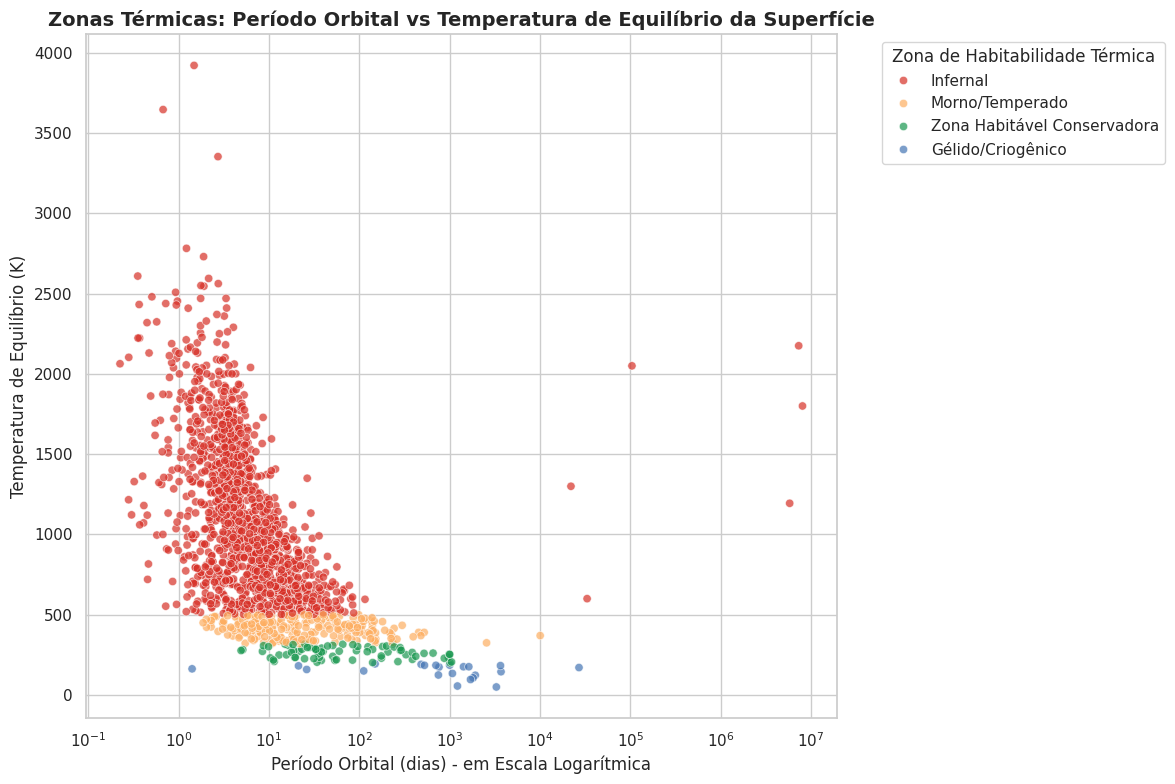

In [143]:
df_plot_termica = df.dropna(subset=[
    'periodo_orbital',
    'temp_equilibrio_superf_planetaria',
    'zona_habitabilidade_termica'
])

plt.figure(figsize=(12, 8))

cores_zonas = {
    'Infernal': '#d73027',                     # Vermelho
    'Morno/Temperado': '#fdae61',              # Laranja
    'Zona Habitável Conservadora': '#1a9850',  # Verde
    'Gélido/Criogênico': '#4575b4'             # Azul
}

sns.scatterplot(
    data=df_plot_termica,
    x='periodo_orbital',
    y='temp_equilibrio_superf_planetaria',
    hue='zona_habitabilidade_termica',
    palette=cores_zonas,
    alpha=0.7,
    edgecolor='w',
    linewidth=0.5
)

plt.title('Zonas Térmicas: Período Orbital vs Temperatura de Equilíbrio da Superfície', fontsize=14, weight='bold')
plt.xlabel('Período Orbital (dias) - em Escala Logarítmica')
plt.ylabel('Temperatura de Equilíbrio (K)')

plt.xscale('log')

plt.legend(title='Zona de Habitabilidade Térmica', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Arquétipos planetários

Também é possível visualizar a relação entre a classificação arquetipo_planetario e os valores de raio_planetario e massa_planetaria, capazes de indicar a estrutura de um exoplaneta. Como tendência geral, quanto maior o raio e massa, mais o planeta irá se parecer com um gigante gasoso como Júpiter; e, quanto menor, mais com um terrestre rochoso.

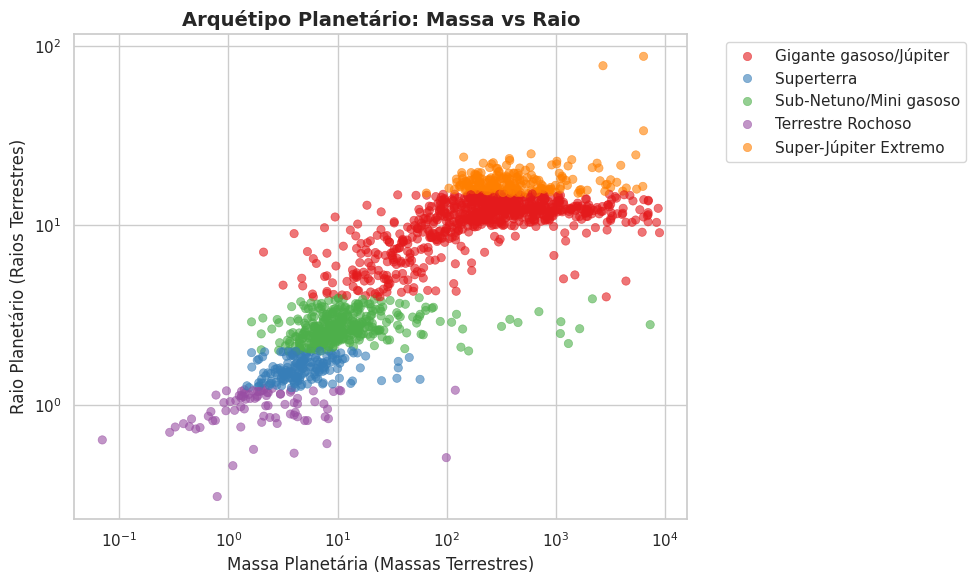

In [144]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
df_plot1 = df.dropna(subset=['massa_planetaria', 'raio_planetario', 'arquetipo_planetario'])

sns.scatterplot(
    data=df_plot1,
    x='massa_planetaria',
    y='raio_planetario',
    hue='arquetipo_planetario',
    palette='Set1',
    alpha=0.6,
    edgecolor=None
)
plt.title('Arquétipo Planetário: Massa vs Raio', fontsize=14, weight='bold')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Massa Planetária (Massas Terrestres)')
plt.ylabel('Raio Planetário (Raios Terrestres)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

##